# Topic Modeling
### Bert Sentence Embedding, LDA, and K-means Clustering

#### Concatenate the sentence embeddings with LDA, use an autoencoder to get the latent representation and perform K-means to perform clustering on the data

#### After the sentences have been assigned to their clusters, we can extract the candidate topics for each cluster using tokens of it's sentences

### 1. Reading and preprocessing the data

In [1]:
from utilities.document_preprocessing import preprocess_documents

#### The preprocess_document function reads the sentences from the file and generates tokens from each sentences.

In [2]:
# Input file
file = 'data/sample_text.txt'

In [3]:
Verbose = True

In [4]:
sentences, token_lists = preprocess_documents(file, verbose = Verbose)

Reading the file
Preprocessing raw texts 



this a very nice blouse
Candidate Tokens:  ['blous']


this a cheap jeans and it got destroyed very quickly
Candidate Tokens:  ['jean']


we all live in munich
Candidate Tokens:  ['munich']


alice in wonderland
Candidate Tokens:  ['alic', 'wonderland']


the weather is very good today
Candidate Tokens:  ['weather', 'today']


alice is not in wonderland
Candidate Tokens:  ['alic', 'wonderland']


i am very happy to announce my new job as a doctor
Candidate Tokens:  ['job', 'doctor']


i love this new blouse and the colors are very vibrant and amazing i love it
Candidate Tokens:  ['blous', 'color']


i like chinese food
Candidate Tokens:  ['food']


harry ron and hermione are best friends
Candidate Tokens:  ['harri', 'ron', 'hermion', 'friend']


i am in love with my new jeans
Candidate Tokens:  ['love', 'jean']


my favorite blouse is blue
Candidate Tokens:  ['blous']


i love pizza and burgers
Candidate Tokens:  ['pizza', 'burger']


the co

### 2. Topic Modeling

In [5]:
from models.topic_model import Topic_Model

#### The topic_Model class does the follow
- Extract Bert sentence embeddings for all sentences (Local features)
- get topic distribution for each sentence using LDA
- concatenate both and learn the latent representation using an auto-encoder
- cluster the latent representation into K clusters

In [6]:
# Define the topic model object
TopicModelObject = Topic_Model(k = 2, verbose = Verbose)

In [7]:
# Fit the topic model
TopicModelObject.fit(sentences, token_lists)

Getting vector representations for LDA 
Dictionary used for LDA 

0 blous
1 jean
2 munich
3 alic
4 wonderland
5 today
6 weather
7 doctor
8 job
9 color
10 food
11 friend
12 harri
13 hermion
14 ron
15 love
16 burger
17 pizza
18 coffe
19 order
20 zalando
21 drink
22 name
23 scientist
24 pink

 Corpus used for LDA 

[(0, 1)]
[(1, 1)]
[(2, 1)]
[(3, 1), (4, 1)]
[(5, 1), (6, 1)]
[(3, 1), (4, 1)]
[(7, 1), (8, 1)]
[(0, 1), (9, 1)]
[(10, 1)]
[(11, 1), (12, 1), (13, 1), (14, 1)]
[(1, 1), (15, 1)]
[(0, 1)]
[(16, 1), (17, 1)]
[(18, 1)]
[(18, 1)]
[(18, 1)]
[(0, 1)]
[(1, 1), (19, 1), (20, 1)]
[(2, 1)]
[(3, 1), (4, 1)]
[(6, 1)]
[(18, 1), (21, 1)]
[(18, 1), (22, 1)]
[(0, 1), (9, 1)]
[(23, 1)]
[(11, 1), (12, 1), (13, 1), (14, 1)]
[(1, 1), (24, 1)]
[(1, 1), (9, 1)]
[(0, 1)]

 
 Shape of LDA Vector:  (29, 2)
[[0.74787575 0.25212422]
 [0.74524468 0.25475529]
 [0.74316102 0.25683901]
 [0.16866484 0.83133519]
 [0.82662964 0.17337038]
 [0.16866484 0.83133519]
 [0.1728411  0.82715893]
 [0.83120298 0.16879702]


In [8]:
labels = set(TopicModelObject.cluster_model.labels_)
for label in labels:
    index = []
    for idx, l in enumerate(TopicModelObject.cluster_model.labels_):
        if l == label:
            index.append(idx)
    print ('\n \nSentences belong to cluster ', str (label+1), ' are: \n ')
    for i in index:
        print (sentences[i])


 
Sentences belong to cluster  1  are: 
 
this a very nice blouse
this a cheap jeans and it got destroyed very quickly
we all live in munich
the weather is very good today
i love this new blouse and the colors are very vibrant and amazing i love it
i am in love with my new jeans
my favorite blouse is blue
the coffee is cold
the coffee is hot
the coffee is tasty
this a very nice blouse
we all live in munich
the weather is very windy
my favorite drink is coffee
my name is coffee
i love this new blouse and the colors are very vibrant and amazing i love it
i hate pink jeans
my favorate jeans in blue color
i was overjoyed when i tried my new blouse

 
Sentences belong to cluster  2  are: 
 
alice in wonderland
alice is not in wonderland
i am very happy to announce my new job as a doctor
i like chinese food
harry ron and hermione are best friends
i love pizza and burgers
this a shitty jeans and i would never order from zalando again
alice in wonderland
i am a scientist
harry ron and hermion

In [9]:
# To get the top words for each topic, this method only uses LDA, doesn't utilize Bert or K mean clustering
TopicModelObject.get_top_words_lda(top=6)

{0: [('blous', 0.1601281),
  ('coffe', 0.13543037),
  ('jean', 0.1315815),
  ('color', 0.08619141),
  ('weather', 0.061276153),
  ('munich', 0.061098523)],
 1: [('wonderland', 0.10101655),
  ('alic', 0.10101019),
  ('ron', 0.072225854),
  ('hermion', 0.07222263),
  ('harri', 0.07222221),
  ('friend', 0.07222167)]}

## Visualizations

In [10]:
from utilities.visualizations import *
%matplotlib inline

/home/anum/anaconda3/envs/nlp/lib/python3.8/site-packages/umap/spectral.py:4: NumbaDeprecationWarning: No direct replacement for 'numba.targets' available. Visit https://gitter.im/numba/numba-dev to request help. Thanks!
  import numba.targets


Getting wordcloud for topic 0 ...
Getting wordcloud for topic 0. Done!
Getting wordcloud for topic 1 ...
Getting wordcloud for topic 1. Done!


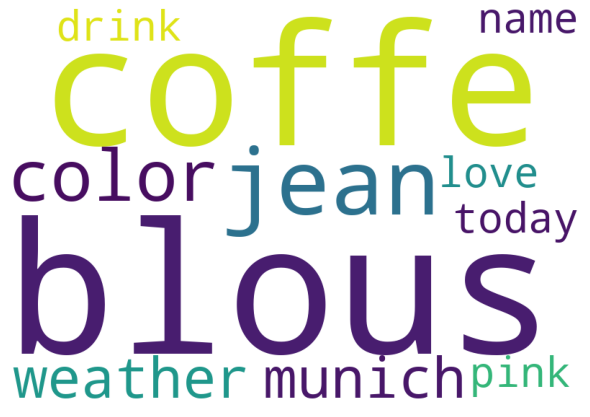

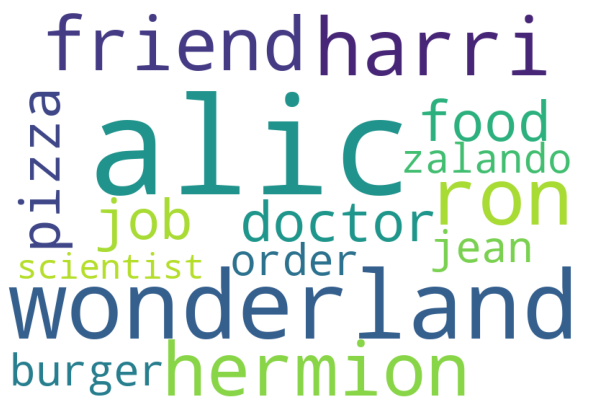

In [11]:
# visualize and save img
#visualize(TopicModelObject)
for i in range(TopicModelObject.k):
    get_wordcloud(TopicModelObject, token_lists, i)